# Регуляризация и выбор моделей: теория и эксперименты

## О проекте

Как регуляризация, масштаб признаков и выбор порога влияют на качество и интерпретацию классических моделей машинного обучения. Работа совмещает теорию и эксперименты: результаты разделов 1–2 проверяются на реальных данных в разделах 3–4.

- **Раздел 1.** Решения OLS, Ridge и Lasso в замкнутой форме, монотонность по $\lambda$ для Ridge, влияние масштаба признака на штраф, свободный член.
- **Раздел 2.** Монотонность precision, recall и accuracy по порогу, порог с минимальной ожидаемой стоимостью ошибок, порог для логистической модели.
- **Раздел 3.** Регрессия на данных Diabetes: базовая линия, чувствительность к масштабу признака, пути регуляризации Ridge и Lasso, выбор модели.
- **Раздел 4.** Классификация на данных Breast Cancer по двум признакам: логистическая регрессия, kNN, SVM и дерево решений, роль масштаба признаков, выбор порога.

### Протокол эксперимента

Разбиения данных фиксированы. Модели и преобразования обучаются только на train, гиперпараметры выбираются по validation. Test используется для финальной оценки после фиксации модели и её настроек; решение по результатам test не меняется. Перед оценкой на test модель не переобучается на train + validation.

## Окружение

In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

SEED = 42
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 130)
pd.set_option("display.precision", 4)
sklearn.set_config(display="text")
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | "
      f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"matplotlib {matplotlib.__version__}")

Python 3.13.15 | NumPy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0


## 1. Теория: регуляризация линейной регрессии

**Постановка.** Признаки и целевая переменная центрированы. Пусть $X\in\mathbb{R}^{n\times d}$ и

$$\frac{X^\top X}{n}=I_d,\qquad \frac{X^\top y}{n}=c.$$

При $\lambda>0$ рассматриваются функции потерь:

$$L_{\mathrm{OLS}}(w)=\frac{1}{2n}\|y-Xw\|_2^2,$$
$$L_{\mathrm{Ridge}}(w)=\frac{1}{2n}\|y-Xw\|_2^2+\frac{\lambda}{2}\|w\|_2^2,$$
$$L_{\mathrm{Lasso}}(w)=\frac{1}{2n}\|y-Xw\|_2^2+\lambda\|w\|_1.$$

**Вопросы.**

1. Решения всех трёх задач минимизации с обоснованием.
2. Монотонность по $\lambda$. Здесь условие $X^\top X/n=I_d$ не предполагается: для произвольной фиксированной матрицы центрированных признаков доказывается, что с ростом $\lambda>0$ евклидова норма оптимального вектора коэффициентов Ridge не возрастает, а обучающая ошибка $\|y-X\hat w_\lambda\|_2^2$ не убывает.
3. Масштаб признака. Столбец $X_j$ умножается на $a=10$, остальные столбцы не меняются. Как изменить коэффициент, чтобы сохранить предсказания? Как изменятся штрафы для того же предсказания? Сохранится ли оптимальное предсказание OLS? Как это преобразование связано со стандартизацией признаков?
4. Свободный член. Если добавить свободный член $b$, следует ли включать его в штраф?

### 1.1. Решения в замкнутой форме
Раскроем квадрат с учётом условий на $X$:

$$\frac{1}{2n}\|y-Xw\|_2^2=\frac{\|y\|_2^2}{2n}-w^\top\frac{X^\top y}{n}+\frac12 w^\top\frac{X^\top X}{n}w=\frac{\|y\|_2^2}{2n}-c^\top w+\frac12\|w\|_2^2.$$

Выделим полный квадрат:

$$\frac{1}{2n}\|y-Xw\|_2^2=\frac12\|w-c\|_2^2+\underbrace{\frac{\|y\|_2^2}{2n}-\frac12\|c\|_2^2}_{\text{const}}.$$

Заметим, что $\|w - c\|_2^2$, $\frac{\lambda}{2}\|w\|_2^2$ — строго выпуклые функции, $\lambda \|w\|_1$ — выпуклая функция. Сумма выпуклой и строго выпуклой функций строго выпукла, а значит все целевые функции строго выпуклы, у них либо нет точек экстремума, либо есть единственный глобальный минимум $\hat{w}$.

#### OLS

$L_{\mathrm{OLS}}(w)=\tfrac12\|w-c\|_2^2+\text{const}$, откуда,
записывая необходимое (и в выпуклом случае достаточное) условие минимума:

$\nabla L_{\mathrm{OLS}}(w) = 0 \implies w - c = 0 \implies$

$\hat w_{\mathrm{OLS}}=c$

#### Ridge

Критерий минимума:

$\nabla L_{\mathrm{Ridge}}(w)=w-c+\lambda w=0.$

Отсюда:

$\hat w_{\mathrm{Ridge}}=\frac{c}{1+\lambda}$

#### Lasso

Задача распадается по координатам:

$L_{\mathrm{Lasso}}(w)=\sum\limits_{j=1}^d\left(\frac12 w_j^2-c_jw_j+\lambda|w_j|\right)+\text{const}$

Критерий минимума через субградиент:

$0\in w_j-c_j+\lambda\,\partial|w_j|,\qquad
\partial|w_j|=
\begin{cases}
\{\operatorname{sign}w_j\}, & w_j\ne0,\\
[-1,1], & w_j=0.
\end{cases}$

Разберём случаи:

- $w_j>0$: тогда $w_j=c_j-\lambda$, что согласовано только при $c_j>\lambda$;
- $w_j<0$: тогда $w_j=c_j+\lambda$, что согласовано только при $c_j<-\lambda$;
- $w_j=0$: нужно $c_j\in[-\lambda,\lambda]$, то есть $|c_j|\le\lambda$.

Случаи покрывают все значения $c_j$ без пересечений. Запишем ответ покоординатно через оператор soft thresholding:

$\hat w_{\mathrm{Lasso},j}=\operatorname{sign}(c_j)\,\big(|c_j|-\lambda\big)_+$

### 1.2. Монотонность по $\lambda$: доказательство
$F(w)=\frac{1}{2n}\|y-Xw\|_2^2,\qquad R(w)=\frac12\|w\|_2^2.$

Пусть $0<\lambda_1<\lambda_2$, $w_1=\hat w_{\lambda_1}$, $w_2=\hat w_{\lambda_2}$. В силу оптимальности точек:

$$F(w_1)+\lambda_1R(w_1)\le F(w_2)+\lambda_1R(w_2),\tag{a}$$

$$F(w_2)+\lambda_2R(w_2)\le F(w_1)+\lambda_2R(w_1).\tag{b}$$

Норма не возрастает: сложим (a) и (b); слагаемые $F$ сокращаются:

$(\lambda_1-\lambda_2)\big(R(w_1)-R(w_2)\big)\le0.$

Так как $\lambda_1-\lambda_2<0$, получаем $R(w_1)\ge R(w_2)$, то есть

$\|\hat w_{\lambda_2}\|_2\le\|\hat w_{\lambda_1}\|_2.$

Ошибка не убывает: из (a) и неравенства выше:

$F(w_1)-F(w_2)\le\lambda_1\big(R(w_2)-R(w_1)\big)\le0,$

то есть

$\|y-X\hat w_{\lambda_1}\|_2^2\le\|y-X\hat w_{\lambda_2}\|_2^2$

### 1.3. Масштаб признака и штраф

Пусть $X'$ — матрица $X$, в которой $j$-й столбец умножили на $a = 10$. Чтобы предсказания сохранились, нам нужно, чтобы $X'w' = Xw$.

То есть для сохранения предсказаний нужно взять $w'$: $w'_j = \frac{w_j}{a}$, $w'_i = w_i$ при $i \neq j$.

Штрафы нужно изменить следующим образом: для Ridge: $\frac{\lambda}{2} \|w\|^2_2 + \left(\frac{1}{a^2} - 1\right)\frac{\lambda}{2}w_j^2$, для Lasso: $\lambda\|w\|_1 + \left(\frac{1}{a} - 1\right)\lambda|w_j|$.

Оптимальное предсказание OLS сохранится: при умножении столбца на $a \neq 0$ пространство столбцов матрицы $X$ не меняется, поэтому оптимальные коэффициенты пересчитываются как $\hat w'_j = \hat w_j / a$, а прогнозы остаются прежними, если новые данные преобразуются так же, то есть их $j$-я координата тоже умножается на $a$.

### 1.4. Свободный член и штраф
Добавим свободный член: $L(w,b)=\frac{1}{2n}\|y-Xw-b\mathbf{1}\|_2^2+\lambda R(w)$, где $\lambda R(w)$ — штраф Ridge или Lasso. Признаки и целевая переменная центрированы, то есть $\mathbf{1}^\top X=0$ и $\mathbf{1}^\top y=0$, поэтому перекрёстное слагаемое обнуляется:

$$\frac{1}{2n}\|y-Xw-b\mathbf{1}\|_2^2=\frac{1}{2n}\|y-Xw\|_2^2+\frac{b^2}{2}.$$

Задача распадается на две независимые: по $w$ и по $b$. По $b$ минимум достигается при $\hat b=0$ — и без штрафа, и со штрафом вида $\mu|b|^p$ ($\mu>0$), который тоже минимален в нуле. Значит, от того, есть ли штраф на $b$ или нет, решение задачи оптимизации и обученные веса не меняются, поэтому штрафовать свободный член нет смысла. Без центрирования штраф тянул бы $\hat b$ к нулю и смещал прогнозы, а результат зависел бы от выбора начала отсчёта $y$, поэтому на практике свободный член не штрафуют.

## 2. Теория: метрики классификации и порог решения

**Постановка.** Положительный класс — $y=1$. Для объектов заданы оценки вероятности $p(x)\in[0,1]$.
Правило классификации: $\hat y=1$, если $p(x)\geq t$, иначе $\hat y=0$.

**Вопросы.**

1. Монотонность метрик. На фиксированной конечной выборке, содержащей оба класса, исследуется монотонность recall, precision и accuracy как функций порога $t$; утверждения обосновываются доказательствами или контрпримерами. Precision рассматривается при наличии положительных предсказаний.
2. Порог по стоимости ошибок. Стоимость верного решения равна 0, ложноположительного — $c_{FP}>0$, ложноотрицательного — $c_{FN}>0$; здесь $p(x)=P(y=1\mid x)$ — истинная условная вероятность. Какой порог минимизирует ожидаемую стоимость ошибки? Обязан ли он минимизировать фактическую стоимость ошибок на любой конечной выборке (доказательство или контрпример)?
3. Порог для логистической модели. Пусть $p(x)=\sigma(w^\top x+b)$, где $\sigma(z)=1/(1+e^{-z})$. Какой порог на $z=w^\top x+b$ соответствует порогу $0<t<1$? При каких условиях порог из пункта 2 применим к прогнозам обученной модели?

### 2.1. Монотонность метрик по порогу

Рассмотрим конечную выборку $\{(x_n, y_n)\}$, содержащую объекты обоих классов.
Пусть $P$ — подмножество положительных объектов, $N$ — подмножество отрицательных объектов, $TP$ — множество верно помеченных положительных объектов, $FP$ — множество неверно помеченных отрицательных объектов, аналогично $TN$, $FN$.

Recall $= \frac{|TP|}{|P|}$

С увеличением порога recall не возрастает.

Precision $= \frac{|TP|}{|TP| + |FP|}$

Монотонности нет в общем случае. Контрпример: с увеличением $t$ сначала «выбывает» ложноположительный объект (precision увеличивается), затем истинно положительный (precision падает).

Accuracy $= \frac{|TP| + |TN|}{|N| + |P|}$

Монотонности нет в общем случае. Контрпример тот же, что и для precision.

### 2.2. Порог с минимальной ожидаемой стоимостью

Пусть $h: x \mapsto \{0, 1\}$ — решающее правило.

Тогда условное матожидание стоимости решения $C$: $\mathbb{E}(C|x) = p(x)(1 - h(x))c_{FN} + (1 - p(x))h(x)c_{FP}$

$p(x)$ — случайная величина, а $h$ — борелевская функция $p$. Тогда удобно перейти к распределению по $p$.

Тогда $\mathbb{E}(C|p) = p(1 - h(p))c_{FN} + (1 - p)h(p)c_{FP}$.

Тогда по формуле полного матожидания и пользуясь тем, что $h(p) = I_{\{p \geqslant t\}}$, получаем:

$\mathbb{E}C = c_{FN}\mathbb{E}p + \mathbb{E}(h(p)(c_{FP} - p(c_{FN} + c_{FP})))$.

Тогда очевидно, что нужно взять такое $t^*$, чтобы $[t^*, 1]$ совпадало с промежутком, на котором $c_{FP} - p(c_{FN} + c_{FP}) \leqslant 0$.

Тогда $t^* = \frac{c_{FP}}{c_{FP} + c_{FN}}$.

Вычисленный порог не обязан минимизировать фактическую стоимость ошибки на любой конечной выборке. Пример: 1 объект с $p > t^*$, но отрицательный.

### 2.3. Порог для логистической модели

$\sigma$ — строго монотонная функция со значениями в (0, 1). Если $\sigma(z) \in (t_1, t_2)$, то $z \in (\ln \frac{t_1}{1 - t_1}, \ln \frac{t_2}{1 - t_2})$. В частности, порогу $t$ на вероятность соответствует порог на $z$: $p(x)\geq t \iff z\geq\ln\frac{t}{1-t}$.

Решая уравнение $\sigma(z) = t^*$, получаем $z = \ln \frac{c_{FP}}{c_{FN}}$.

Для того, чтобы порог был применим, достаточно, чтобы $\mathbb{P}(y = 1 | p(x) = p) = p$, так как порог был выведен исходя из распределения по $p$, а не по $x$.

## 3. Эксперименты: регрессия на данных Diabetes

**Данные.** Набор `Diabetes`: 442 наблюдения, 10 признаков и численный
показатель прогрессирования диабета через год. Признаки: `age` — возраст,
`sex` — пол, `bmi` — индекс массы тела, `bp` — среднее артериальное давление,
`s1`–`s6` — лабораторные показатели. Данные загружаются с `scaled=False`.
Разбиение train / validation / test — приблизительно 60 / 20 / 20%; финальная оценка на test — в пункте 3.5.
[Описание данных](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html).

**Модели.** OLS — линейная регрессия методом наименьших квадратов,
Ridge — линейная регрессия с L2-регуляризацией и Lasso — с L1-регуляризацией.
Базовая модель — `DummyRegressor`, предсказывающий
среднее значение целевой переменной на обучающей выборке.

In [ ]:
from IPython.display import Markdown as reg_Markdown
from sklearn.datasets import load_diabetes as reg_load_diabetes
from sklearn.dummy import DummyRegressor as reg_DummyRegressor
from sklearn.linear_model import (
    LinearRegression as reg_LinearRegression,
    Ridge as reg_Ridge,
    Lasso as reg_Lasso,
)
from sklearn.metrics import mean_squared_error as reg_mean_squared_error
from sklearn.model_selection import train_test_split as reg_train_test_split
from sklearn.pipeline import Pipeline as reg_Pipeline
from sklearn.preprocessing import StandardScaler as reg_StandardScaler

reg_dataset = reg_load_diabetes(as_frame=True, scaled=False)
reg_X_train, reg_X_holdout, reg_y_train, reg_y_holdout = reg_train_test_split(
    reg_dataset.data, reg_dataset.target, test_size=0.4, random_state=SEED
)
reg_X_valid, reg_X_test, reg_y_valid, reg_y_test = reg_train_test_split(
    reg_X_holdout, reg_y_holdout, test_size=0.5, random_state=SEED
)
del reg_dataset, reg_X_holdout, reg_y_holdout

def reg_rmse(y_true, y_pred):
    return float(np.sqrt(reg_mean_squared_error(y_true, y_pred)))

print(f"Train: {len(reg_y_train)}; validation: {len(reg_y_valid)}; "
      f"test: {len(reg_y_test)} наблюдений.")

Train: 265; validation: 88; test: 89 наблюдений.


### 3.1. Разведочный анализ

На train проверяются пропуски, повторяющиеся строки и диапазоны признаков;
строится диаграмма `bmi`–`target` и вычисляются корреляции между признаками.

1. Насколько различаются численные масштабы признаков?
2. Как интерпретировать числовые значения `sex`? Достаточно ли одного столбца для представления этого признака в линейной модели со свободным членом?
3. Какая пара признаков тесно коррелирует и как такая связь влияет на интерпретацию коэффициентов линейной модели?
4. Можно ли сделать вывод о причинном влиянии `bmi` на ответ?

In [ ]:
reg_train = reg_X_train.assign(target=reg_y_train)

print(f"Пропуски: {int(reg_train.isna().sum().sum())}")
print(f"Повторяющиеся строки (признаки + target): {int(reg_train.duplicated().sum())}")
print(f"Повторяющиеся строки (только признаки): {int(reg_X_train.duplicated().sum())}")

reg_ranges = reg_train.agg(["min", "max", "mean", "std"]).T
reg_ranges["range"] = reg_ranges["max"] - reg_ranges["min"]
reg_ranges["n_unique"] = reg_train.nunique()
display(reg_ranges.round(2))

Пропуски: 0
Повторяющиеся строки (признаки + target): 0
Повторяющиеся строки (только признаки): 0


,min,max,mean,std,range,n_unique
age,19.0,79.00,48.69,12.98,60.00,56
sex,1.0,2.00,1.46,0.50,1.00,2
bmi,18.6,41.30,26.61,4.45,22.70,137
bp,62.0,133.00,94.79,13.97,71.00,83
s1,110.0,301.00,189.97,35.05,191.00,115
s2,41.6,242.40,115.53,30.62,200.80,210
s3,22.0,99.00,50.06,13.15,77.00,59
s4,2.0,9.09,4.07,1.30,7.09,40
s5,3.5,6.11,4.66,0.52,2.61,143
s6,58.0,124.00,91.72,11.36,66.00,53


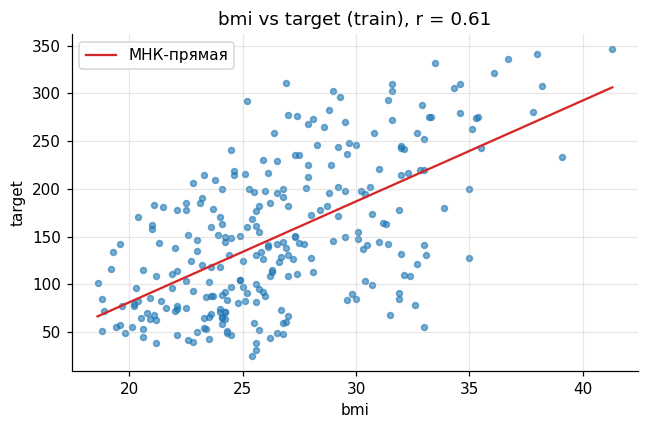

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(reg_X_train["bmi"], reg_y_train, s=15, alpha=0.6)

reg_slope, reg_intercept = np.polyfit(reg_X_train["bmi"], reg_y_train, deg=1)
reg_grid = np.linspace(reg_X_train["bmi"].min(), reg_X_train["bmi"].max(), 100)
ax.plot(reg_grid, reg_intercept + reg_slope * reg_grid, color="C3", label="МНК-прямая")

reg_r = reg_X_train["bmi"].corr(reg_y_train)
ax.set(xlabel="bmi", ylabel="target", title=f"bmi vs target (train), r = {reg_r:.2f}")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

# Разбиение на квартили: в каждой группе ~25% наблюдений train
reg_bmi_bins = pd.qcut(reg_X_train["bmi"], q=4)
reg_target_bins = pd.qcut(reg_y_train, q=4)
reg_table = pd.crosstab(reg_bmi_bins, reg_target_bins)
display(reg_table)

reg_chi2, reg_p_value, reg_dof, reg_expected = chi2_contingency(reg_table)
reg_n = reg_table.values.sum()
reg_cramers_v = np.sqrt(reg_chi2 / (reg_n * (min(reg_table.shape) - 1)))

print(f"chi2 = {reg_chi2:.2f}, df = {reg_dof}, p-value = {reg_p_value:.2e}")
print(f"Минимальная ожидаемая частота: {reg_expected.min():.1f}")
print(f"V Крамера = {reg_cramers_v:.2f}")

target,"(24.999, 85.0]","(85.0, 141.0]","(141.0, 202.0]","(202.0, 346.0]"
bmi,,,,
"(18.599, 23.5]",34,18,14,2
"(23.5, 25.9]",21,19,18,7
"(25.9, 29.6]",8,15,22,21
"(29.6, 41.3]",5,13,13,35


chi2 = 75.82, df = 9, p-value = 1.09e-12
Минимальная ожидаемая частота: 15.9
V Крамера = 0.31


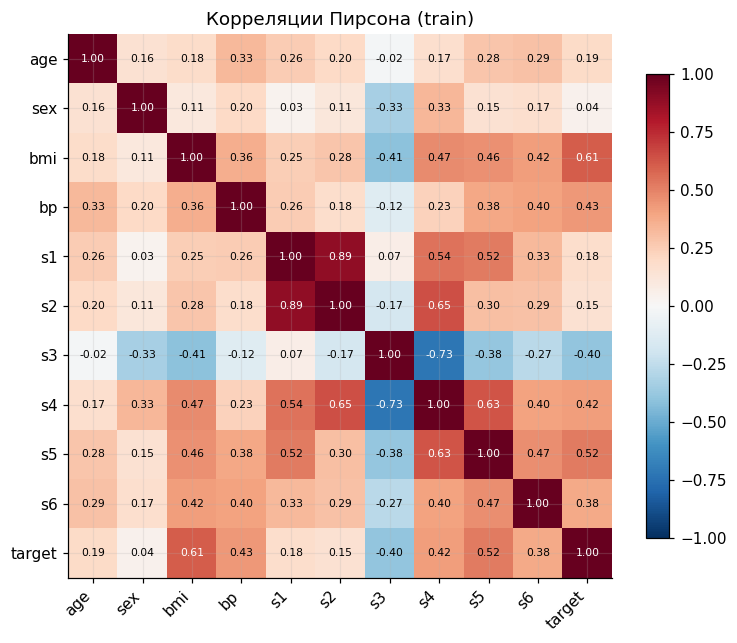

s1  s2    0.89
s3  s4   -0.73
s2  s4    0.65
s4  s5    0.63
s1  s4    0.54
dtype: float64
bmi    0.61
s5     0.52
bp     0.43
s4     0.42
s3    -0.40
s6     0.38
age    0.19
s1     0.18
s2     0.15
sex    0.04
Name: target, dtype: float64


In [ ]:
reg_corr = reg_train.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(reg_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(reg_corr)), reg_corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(reg_corr)), reg_corr.columns)
for i in range(len(reg_corr)):
    for j in range(len(reg_corr)):
        v = reg_corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Корреляции Пирсона (train)")
plt.tight_layout()
plt.show()

# Самые сильные пары признаков и связь признаков с target
reg_mask = np.triu(np.ones(reg_corr.shape[0] - 1, dtype=bool), k=1)
reg_pairs = (reg_corr.drop(index="target", columns="target")
             .where(reg_mask).stack())
print(reg_pairs.reindex(reg_pairs.abs().sort_values(ascending=False).index).head(5).round(2))
print(reg_corr["target"].drop("target").sort_values(key=abs, ascending=False).round(2))

1. Диапазоны, в которых меняются признаки, различаются максимум примерно в 200 раз, средние значения — примерно в 130 раз; в обоих случаях максимум достигается в паре с бинарным `sex`. Среди непрерывных признаков стандартные отклонения различаются примерно в 67 раз (`s1` и `s5`).
2. Sex — это пол (мужской или женский), соответственно 2 значения (1 и 2). Для его представления достаточно одного столбца. Дробление этого признака на 2 или больше даст линейную зависимость признаков, что априорно ухудшает качество модели.
3. $s_1$ и $s_2$ тесно скоррелированы. Это повышает дисперсию предсказаний и повышает чувствительность к ошибкам. В предельном случае получаем линейную зависимость признаков и линейное подпространство решений. А потому нужна регуляризация.
4. Можно сделать вывод о том, что высокий bmi способствует развитию диабета. По крайней мере, можно заметить, что он наиболее сильно скоррелирован с target. Чтобы количественно оценить качество прогноза, можно посчитать статистику критерия $\chi^2$ и найти p-value. Оказалось, что данные не противоречат гипотезе.


### 3.2. Базовая линия: Dummy и OLS

На train обучаются `DummyRegressor(strategy="mean")` и `LinearRegression` (OLS);
OLS — в `Pipeline` со `StandardScaler`. RMSE обеих моделей на validation сведены в таблицу,
обученные модели сохраняются для финальной оценки в пункте 3.5.

$$\operatorname{RMSE}=\sqrt{\frac1m\sum_{i=1}^{m}(y_i-\hat y_i)^2}.$$

Как интерпретировать сравнение с Dummy? Почему среднее для Dummy
и параметры scaler должны вычисляться по train?

In [ ]:
# Обученные модели хранятся в словаре: они понадобятся в пункте 3.5 для оценки на test
reg_models = {
    "Dummy (mean)": reg_DummyRegressor(strategy="mean"),
    "OLS": reg_Pipeline([
        ("scaler", reg_StandardScaler()),
        ("model", reg_LinearRegression()),
    ]),
}

reg_rows = []
for reg_name, reg_model in reg_models.items():
    reg_model.fit(reg_X_train, reg_y_train)   # scaler обучается только на train
    reg_rows.append({
        "Модель": reg_name,
        "RMSE train": reg_rmse(reg_y_train, reg_model.predict(reg_X_train)),
        "RMSE validation": reg_rmse(reg_y_valid, reg_model.predict(reg_X_valid)),
    })

reg_results = pd.DataFrame(reg_rows).set_index("Модель")
display(reg_results.round(2))

,RMSE train,RMSE validation
Модель,,
Dummy (mean),77.33,76.16
OLS,54.28,49.15


1. Dummy regressor просто считает среднее. Если модель хуже Dummy и на train, и на test, то у неё достаточно плохая обобщающая способность: она не извлекает из признаков полезной информации. На train OLS не может быть хуже Dummy: Dummy — частный случай линейной модели (все веса нулевые), а OLS минимизирует ошибку на train среди всех линейных моделей. На validation и test это не гарантировано.
2. Чтобы можно было оценить предсказательную силу модели, нельзя смешивать train, validation и test. Поэтому стандартизация признаков и тренировка модели должны проводиться строго по train.

### 3.3. Чувствительность к масштабу признака

В копиях train и validation только `bmi` умножается на `1000`.
Сравниваются четыре варианта:

- OLS без стандартизации;
- OLS со `StandardScaler`;
- `Ridge(alpha=1000)` без стандартизации;
- `Ridge(alpha=1000)` со `StandardScaler`.

Для каждого варианта обучаются отдельные модели на исходных и преобразованных
данных; validation берётся в тех же единицах, что и соответствующий train.

Четыре диаграммы: по горизонтали — прогноз на исходных данных,
по вертикали — прогноз после преобразования для того же объекта;
на каждой панели диагональ $y=x$ и одинаковый масштаб осей.

1. В каких вариантах изменились прогнозы и почему?
2. Как преобразование признака связано с коэффициентом при `bmi` и штрафом Ridge?
3. Какова роль стандартизации в этом эксперименте? Гарантирует ли она снижение ошибки при фиксированном `alpha`?

,RMSE valid (исходные),RMSE valid (bmi×1000),max |Δ прогноза|
Вариант,,,
OLS без стандартизации,49.1497,49.1497,0.0000
OLS + StandardScaler,49.1497,49.1497,0.0000
Ridge(α=1000) без стандартизации,52.2432,52.3256,20.0203
Ridge(α=1000) + StandardScaler,61.9594,61.9594,0.0000


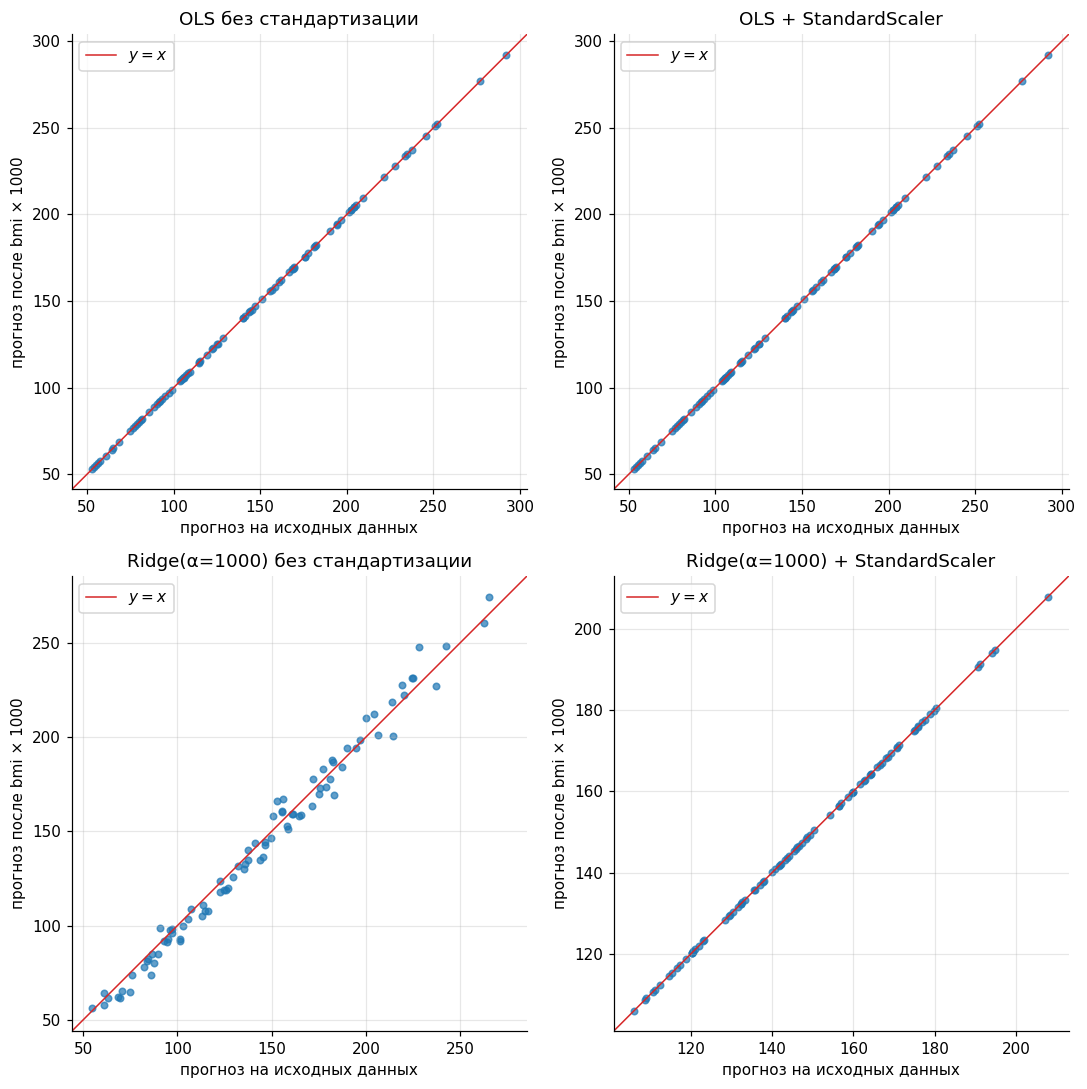

In [ ]:
from sklearn.base import clone as reg_clone

# Копии train и validation, в которых bmi умножен на 1000
reg_X_train_bmi = reg_X_train.copy()
reg_X_valid_bmi = reg_X_valid.copy()
reg_X_train_bmi["bmi"] *= 1000
reg_X_valid_bmi["bmi"] *= 1000

reg_scale_variants = {
    "OLS без стандартизации": reg_LinearRegression(),
    "OLS + StandardScaler": reg_Pipeline([
        ("scaler", reg_StandardScaler()), ("model", reg_LinearRegression())]),
    "Ridge(α=1000) без стандартизации": reg_Ridge(alpha=1000),
    "Ridge(α=1000) + StandardScaler": reg_Pipeline([
        ("scaler", reg_StandardScaler()), ("model", reg_Ridge(alpha=1000))]),
}

reg_scale_preds, reg_scale_rows = {}, []
for reg_name, reg_template in reg_scale_variants.items():
    # Отдельная модель для исходных данных и отдельная для bmi × 1000
    reg_m_orig = reg_clone(reg_template).fit(reg_X_train, reg_y_train)
    reg_m_bmi = reg_clone(reg_template).fit(reg_X_train_bmi, reg_y_train)

    # Validation в тех же единицах, что и соответствующий train
    reg_p_orig = reg_m_orig.predict(reg_X_valid)
    reg_p_bmi = reg_m_bmi.predict(reg_X_valid_bmi)

    reg_scale_preds[reg_name] = (reg_p_orig, reg_p_bmi)
    reg_scale_rows.append({
        "Вариант": reg_name,
        "RMSE valid (исходные)": reg_rmse(reg_y_valid, reg_p_orig),
        "RMSE valid (bmi×1000)": reg_rmse(reg_y_valid, reg_p_bmi),
        "max |Δ прогноза|": float(np.max(np.abs(reg_p_orig - reg_p_bmi))),
    })

display(pd.DataFrame(reg_scale_rows).set_index("Вариант").round(4))

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, (reg_name, (reg_p_orig, reg_p_bmi)) in zip(axes.ravel(), reg_scale_preds.items()):
    ax.scatter(reg_p_orig, reg_p_bmi, s=18, alpha=0.7)

    # Одинаковые пределы по обеим осям и диагональ y = x
    reg_lo = min(reg_p_orig.min(), reg_p_bmi.min())
    reg_hi = max(reg_p_orig.max(), reg_p_bmi.max())
    reg_pad = 0.05 * (reg_hi - reg_lo)
    reg_lims = (reg_lo - reg_pad, reg_hi + reg_pad)
    ax.plot(reg_lims, reg_lims, color="C3", lw=1, label="$y=x$")
    ax.set_xlim(reg_lims)
    ax.set_ylim(reg_lims)
    ax.set_aspect("equal")

    ax.set(title=reg_name, xlabel="прогноз на исходных данных",
           ylabel="прогноз после bmi × 1000")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

1. Прогноз изменился только для Ridge без стандартизации. Это можно легко объяснить: на OLS линейное невырожденное преобразование признаков не влияет, оно может повлиять лишь на модели со штрафом и их предсказание. Стандартизация признаков позволяет избежать этого эффекта.
2. Линейное преобразование признаков для OLS влечет обратное преобразование коэффициентов (замена координат в сопряженном пространстве). Масштабирование признака влечет обратное масштабирование коэффициента, ему соответствующего, и уменьшает влияние штрафа Ridge на него (и именно поэтому предсказание с Ridge без стандартизации дает меньшую ошибку RMSE).
3. Стандартизация позволяет сделать модель устойчивой к изменению масштабов признаков. Снижение ошибки при фиксированном $\alpha$ она не влечет. Более того, если масштаб признаков уменьшился, а $\alpha$ достаточно большое, то ошибка может увеличиться.

### 3.4. Пути регуляризации Ridge и Lasso

На исходных признаках обучаются модели в `Pipeline` со `StandardScaler`:

- Ridge: `alpha = [0.1, 1, 10, 100, 1000, 10000]`;
- Lasso: `alpha = [0.01, 0.1, 1, 3, 10, 30, 100]`, `max_iter=20000`.

Для каждого значения сохраняются модель, коэффициенты, train RMSE и validation RMSE.
Рисунок из четырёх панелей: в верхнем ряду — зависимости ошибок
от `alpha` для двух моделей, в нижнем — зависимости их коэффициентов от `alpha`;
ось `alpha` логарифмическая, на графиках коэффициентов — линия нуля.

1. Как регуляризация влияет на train RMSE и validation RMSE и чем объясняется форма полученных кривых?
2. Верно ли по графикам утверждение «При усилении Ridge-регуляризации каждый коэффициент не возрастает по модулю»? Как результат связан с пунктом 1.2? Как ведёт себя Lasso: есть ли нулевые коэффициенты и что можно заключить о соответствующих признаках?
3. Как `alpha` в документации [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) и [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) связан с $\lambda$ из раздела 1? Можно ли сравнивать силу двух видов регуляризации по одинаковому числу `alpha`?
4. Как интерпретировать знак и величину коэффициента `bmi` у Lasso при `alpha=1`? Можно ли считать модуль коэффициента мерой важности признака?

Ridge


,RMSE train,RMSE validation,ненулевых коэф.
alpha,,,
0.1,54.29,49.16,10
1.0,54.30,49.20,10
10.0,54.40,49.37,10
100.0,55.44,50.81,10
1000.0,64.44,61.96,10
10000.0,74.78,73.41,10


Lasso


,RMSE train,RMSE validation,ненулевых коэф.
alpha,,,
0.01,54.29,49.16,10
0.10,54.30,49.20,10
1.00,54.47,49.53,8
3.00,55.02,50.73,6
10.00,57.39,53.82,4
30.00,67.67,66.03,2
100.00,77.33,76.16,0


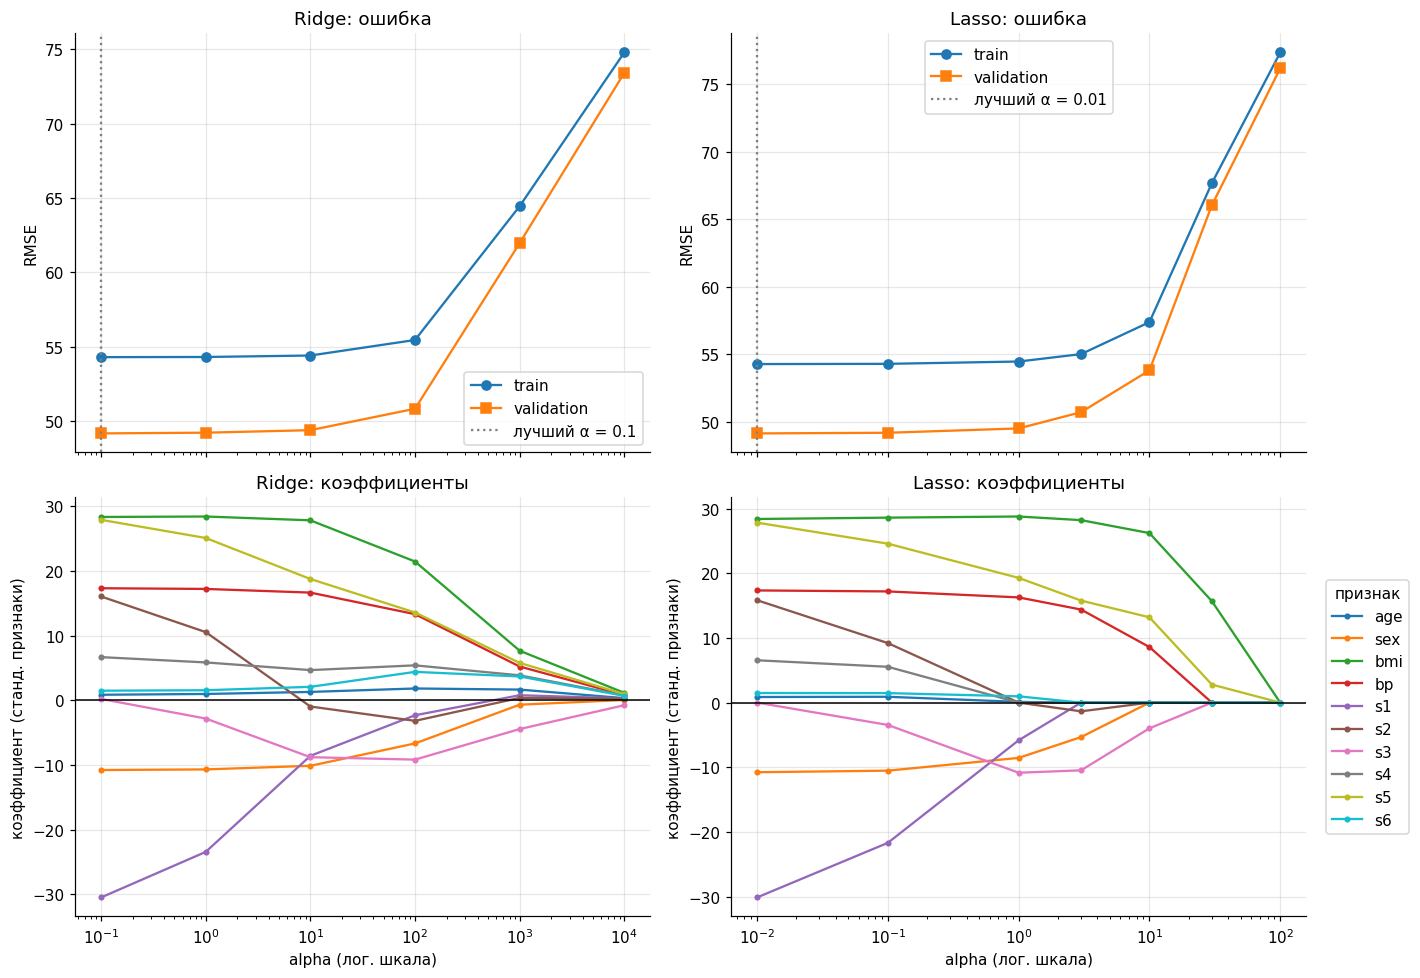

In [ ]:
reg_alpha_grid = {
    "Ridge": [0.1, 1, 10, 100, 1000, 10000],
    "Lasso": [0.01, 0.1, 1, 3, 10, 30, 100],
}

def reg_make_model(reg_kind, reg_alpha):
    reg_est = (reg_Ridge(alpha=reg_alpha) if reg_kind == "Ridge"
               else reg_Lasso(alpha=reg_alpha, max_iter=20000))
    return reg_Pipeline([("scaler", reg_StandardScaler()), ("model", reg_est)])

# Для каждого alpha: модель, коэффициенты, RMSE на train и validation
reg_path = {"Ridge": [], "Lasso": []}
for reg_kind, reg_alphas in reg_alpha_grid.items():
    for reg_alpha in reg_alphas:
        reg_model = reg_make_model(reg_kind, reg_alpha).fit(reg_X_train, reg_y_train)
        reg_path[reg_kind].append({
            "alpha": reg_alpha,
            "model": reg_model,
            "coef": pd.Series(reg_model.named_steps["model"].coef_, index=reg_X_train.columns),
            "rmse_train": reg_rmse(reg_y_train, reg_model.predict(reg_X_train)),
            "rmse_valid": reg_rmse(reg_y_valid, reg_model.predict(reg_X_valid)),
        })

reg_path_tables = {}
for reg_kind, reg_rows in reg_path.items():
    reg_path_tables[reg_kind] = pd.DataFrame([{
        "alpha": r["alpha"],
        "RMSE train": r["rmse_train"],
        "RMSE validation": r["rmse_valid"],
        "ненулевых коэф.": int((r["coef"] != 0).sum()),
    } for r in reg_rows]).set_index("alpha")
    print(reg_kind)
    display(reg_path_tables[reg_kind].round(2))

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex="col")
for reg_col, reg_kind in enumerate(["Ridge", "Lasso"]):
    reg_rows = reg_path[reg_kind]
    reg_alphas = [r["alpha"] for r in reg_rows]

    # Верхний ряд: ошибки
    ax = axes[0, reg_col]
    ax.plot(reg_alphas, [r["rmse_train"] for r in reg_rows], "o-", label="train")
    ax.plot(reg_alphas, [r["rmse_valid"] for r in reg_rows], "s-", label="validation")
    reg_best = min(reg_rows, key=lambda r: r["rmse_valid"])
    ax.axvline(reg_best["alpha"], color="gray", ls=":", label=f"лучший α = {reg_best['alpha']}")
    ax.set(xscale="log", ylabel="RMSE", title=f"{reg_kind}: ошибка")
    ax.grid(alpha=0.3)
    ax.legend()

    # Нижний ряд: коэффициенты
    ax = axes[1, reg_col]
    reg_coefs = pd.DataFrame([r["coef"] for r in reg_rows], index=reg_alphas)
    for reg_feat in reg_coefs.columns:
        ax.plot(reg_alphas, reg_coefs[reg_feat], "o-", ms=3, label=reg_feat)
    ax.axhline(0, color="black", lw=1)
    ax.set(xscale="log", xlabel="alpha (лог. шкала)",
           ylabel="коэффициент (станд. признаки)", title=f"{reg_kind}: коэффициенты")
    ax.grid(alpha=0.3)

axes[1, 1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), title="признак")
plt.tight_layout()
plt.show()

In [ ]:
reg_lasso_1 = next(r for r in reg_path["Lasso"] if r["alpha"] == 1)
reg_scaler = reg_lasso_1["model"].named_steps["scaler"]
reg_j = list(reg_X_train.columns).index("bmi")

reg_w_std = reg_lasso_1["coef"]["bmi"]                 # на 1 std bmi
reg_sigma_bmi = reg_scaler.scale_[reg_j]
reg_w_orig = reg_w_std / reg_sigma_bmi                 # на 1 единицу ИМТ
reg_q25, reg_q75 = reg_X_train["bmi"].quantile([0.25, 0.75])

reg_ols = reg_models["OLS"]
reg_w_ols = reg_ols.named_steps["model"].coef_[reg_j]
reg_slope_pair = np.polyfit(reg_X_train["bmi"], reg_y_train, deg=1)[0]

print(f"Знак: {'положительный' if reg_w_std > 0 else 'отрицательный' if reg_w_std < 0 else 'ноль'}")
print(f"Ранг по |коэф.| среди признаков: {int(reg_lasso_1['coef'].abs().rank(ascending=False)['bmi'])}")
print(f"Коэффициент (станд. признаки): {reg_w_std:.2f} на 1 std bmi (σ = {reg_sigma_bmi:.2f}), "
      f"это {reg_w_std / reg_y_train.std(ddof=0):.2f} σ_y")
print(f"В исходных единицах: {reg_w_orig:.2f} на 1 единицу ИМТ")
print(f"Переход от Q1 ({reg_q25:.1f}) к Q3 ({reg_q75:.1f}): +{reg_w_orig * (reg_q75 - reg_q25):.1f} к прогнозу")

display(pd.DataFrame({
    "коэф. (станд.)": [np.nan, reg_w_ols, reg_w_std],
    "на 1 ед. ИМТ": [reg_slope_pair, reg_w_ols / reg_sigma_bmi, reg_w_orig],
}, index=["Парная регрессия target ~ bmi", "OLS (все признаки)", "Lasso, α=1"]).round(2))

display(reg_lasso_1["coef"].sort_values(key=abs, ascending=False).round(2).to_frame("Lasso, α=1"))

Знак: положительный
Ранг по |коэф.| среди признаков: 1
Коэффициент (станд. признаки): 28.76 на 1 std bmi (σ = 4.44), это 0.37 σ_y
В исходных единицах: 6.48 на 1 единицу ИМТ
Переход от Q1 (23.5) к Q3 (29.6): +39.5 к прогнозу


,коэф. (станд.),на 1 ед. ИМТ
Парная регрессия target ~ bmi,NaN,10.57
OLS (все признаки),28.35,6.38
"Lasso, α=1",28.76,6.48


,"Lasso, α=1"
bmi,28.76
s5,19.28
bp,16.26
s3,-10.84
sex,-8.55
s1,-5.82
s6,0.97
age,0.11
s2,-0.00
s4,0.00


1. С ростом $\alpha$ RMSE растет, причем это верно для всякого возрастающего по $\alpha$ штрафа. Это доказано в пункте 1.2.
2. При усилении Ridge-регуляризации коэффициенты могут возрастать по модулю, и утверждение неверно, что можно увидеть по графику. В пункте 1.2 доказано, что 2-норма вектора коэффициентов при усилении Ridge-регуляризации не возрастает. Также оказывается, что при Lasso-регуляризации 1-норма вектора коэффициентов не возрастает. Оказывается также, что, в отличие от модели с Lasso-регуляризацией, все коэффициенты в модели с Ridge-регуляризацией всегда ненулевые. Для Lasso-регуляризации верно, что чем сильнее признак влияет на target, тем позже он зануляется при усилении регуляризации — здесь это bmi и $s_5$.
3. В scikit-learn Ridge минимизирует $\|y-Xw\|_2^2+\alpha\|w\|_2^2$, а Lasso — $\frac{1}{2n}\|y-Xw\|_2^2+\alpha\|w\|_1$. Умножив $L_{\mathrm{Ridge}}$ из раздела 1 на $2n$ и сравнив, получаем $\alpha^{Ridge}_{sklearn}=n\lambda$ и $\alpha^{Lasso}_{sklearn}=\lambda$, где $n$ — размер обучающей выборки. При $n=265$ значение `alpha=1000` у Ridge соответствует $\lambda\approx3.8$. Поэтому сравнивать силу двух видов регуляризации по одинаковому числу $\alpha$ некорректно — и со стандартизацией, и без: у моделей разный масштаб функции потерь (множитель $\frac{1}{2n}$ есть только у Lasso) и разный вид штрафа (квадрат $L_2$-нормы против $L_1$-нормы).

4. Коэффициент у bmi — положительный и наибольший по модулю, а значит это наиболее важный признак в модели. Более того, в модели с Lasso-регуляризацией всегда можно считать, что чем больше коэффициент по модулю, тем он важнее — во-первых, изменение его сильнее уменьшает RMSE при зафиксированных остальных коэффициентах, чем изменение меньшего по модулю коэффициента, во-вторых, при усилении регуляризации он позже зануляется.

### 3.5. Выбор модели и финальная оценка на test

По результатам 3.2 и 3.4 выбирается OLS или одна из моделей Ridge/Lasso
со `StandardScaler`; выбор фиксируется и обосновывается до обращения к test.

Для выбранной обученной модели вычисляется test RMSE и строится график фактических
значений против прогнозов с диагональю либо остатков против прогнозов с линией нуля.

Что показывает график и каковы ограничения модели или проведённого эксперимента?

,RMSE train,RMSE validation,RMSE test
OLS,54.28,49.15,56.97
"Dummy (mean), для сравнения",77.33,76.16,76.91


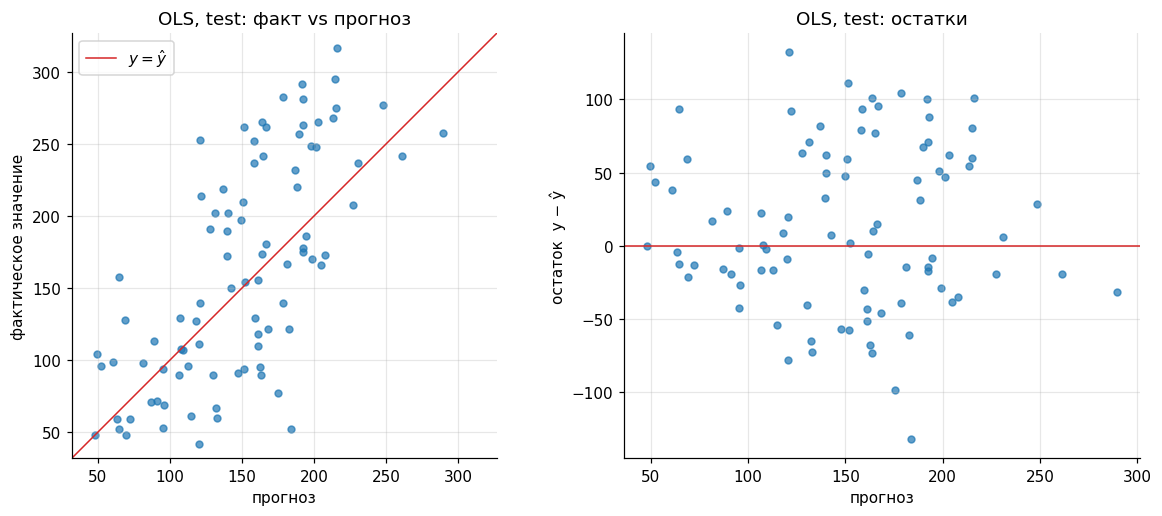

In [ ]:
# Выбор зафиксирован до обращения к test
reg_final_name = "OLS"
reg_final_model = reg_models[reg_final_name]

reg_pred_test = reg_final_model.predict(reg_X_test)
reg_resid_test = reg_y_test - reg_pred_test

reg_compare = [reg_final_model, reg_models["Dummy (mean)"]]
reg_final_table = pd.DataFrame({
    "RMSE train": [reg_rmse(reg_y_train, m.predict(reg_X_train)) for m in reg_compare],
    "RMSE validation": [reg_rmse(reg_y_valid, m.predict(reg_X_valid)) for m in reg_compare],
    "RMSE test": [reg_rmse(reg_y_test, m.predict(reg_X_test)) for m in reg_compare],
}, index=[reg_final_name, "Dummy (mean), для сравнения"])
display(reg_final_table.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

# Фактические значения против прогнозов
ax = axes[0]
ax.scatter(reg_pred_test, reg_y_test, s=20, alpha=0.7)
reg_lims = [min(reg_pred_test.min(), reg_y_test.min()) - 10,
            max(reg_pred_test.max(), reg_y_test.max()) + 10]
ax.plot(reg_lims, reg_lims, color="C3", lw=1, label=r"$y=\hat y$")
ax.set(xlim=reg_lims, ylim=reg_lims, aspect="equal",
       xlabel="прогноз", ylabel="фактическое значение",
       title=f"{reg_final_name}, test: факт vs прогноз")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")

# Остатки против прогнозов
ax = axes[1]
ax.scatter(reg_pred_test, reg_resid_test, s=20, alpha=0.7)
ax.axhline(0, color="C3", lw=1)
ax.set(xlabel="прогноз", ylabel="остаток  y − ŷ",
       title=f"{reg_final_name}, test: остатки")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Как можно увидеть по графикам, модель сильно зашумлена, что свидетельствует о том, что либо сами данные зашумлены, либо линейная модель с конкретными выбранными параметрами задаче подходит недостаточно хорошо.

## 4. Эксперименты: классификация на данных Breast Cancer

**Данные.** Набор Wisconsin Diagnostic Breast Cancer содержит 30 числовых
характеристик клеточных ядер; во всех экспериментах используются только `mean radius`
и `mean texture`. Целевая переменная перекодирована:
`1 = malignant` (злокачественная опухоль), `0 = benign` (доброкачественная опухоль).
Стратифицированное разбиение train / validation / test — 60 / 20 / 20%;
финальная оценка на test — в пункте 4.5.
[Описание данных](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).

**Модели.**

- логистическая регрессия — модель вероятности класса с сигмоидой от линейной комбинации признаков;
- kNN — классификация по меткам ближайших соседей;
- SVM с RBF-ядром — метод опорных векторов с гауссовым ядром;
- дерево решений — последовательность разбиений по значениям признаков.

In [ ]:
from IPython.display import Markdown as cls_Markdown
from sklearn.datasets import load_breast_cancer as cls_load_data
from sklearn.dummy import DummyClassifier as cls_DummyClassifier
from sklearn.linear_model import LogisticRegression as cls_LogisticRegression
from sklearn.neighbors import KNeighborsClassifier as cls_KNeighborsClassifier
from sklearn.svm import SVC as cls_SVC
from sklearn.tree import DecisionTreeClassifier as cls_DecisionTreeClassifier
from sklearn.pipeline import Pipeline as cls_Pipeline
from sklearn.preprocessing import StandardScaler as cls_StandardScaler
from sklearn.model_selection import train_test_split as cls_train_test_split
from sklearn.metrics import (
    balanced_accuracy_score as cls_balanced_accuracy_score,
    precision_score as cls_precision_score,
    recall_score as cls_recall_score,
    confusion_matrix as cls_confusion_matrix,
    ConfusionMatrixDisplay as cls_ConfusionMatrixDisplay,
)

cls_data = cls_load_data(as_frame=True)
cls_features = ["mean radius", "mean texture"]
cls_X = cls_data.data[cls_features].copy()
cls_y = (cls_data.target == 0).astype(int).rename("malignant")
cls_X_dev, cls_X_test, cls_y_dev, cls_y_test = cls_train_test_split(
    cls_X, cls_y, test_size=0.20, stratify=cls_y, random_state=SEED
)
cls_X_train, cls_X_val, cls_y_train, cls_y_val = cls_train_test_split(
    cls_X_dev, cls_y_dev, test_size=0.25, stratify=cls_y_dev, random_state=SEED
)
assert set(cls_X_train.index).isdisjoint(cls_X_val.index)
assert set(cls_X_train.index).isdisjoint(cls_X_test.index)
assert set(cls_X_val.index).isdisjoint(cls_X_test.index)
print("Число объектов train / validation / test:",
      len(cls_X_train), len(cls_X_val), len(cls_X_test))

Число объектов train / validation / test: 341 114 114


**Визуализация границ.** Функция `cls_plot_boundaries(models, titles=None, radius_multipliers=None, mark_errors=True)`
принимает словарь «название → обученная модель» и строит области предсказанных классов.
На графике отображаются train-объекты и, при `mark_errors=True`, ошибки validation.
`titles` задаёт подписи, `radius_multipliers` — множители радиуса на входе каждой модели.
Координаты графика соответствуют исходным единицам признаков.

In [ ]:
cls_colors = {0: "#2a788e", 1: "#c95a47"}
cls_names = {0: "benign (0)", 1: "malignant (1)"}
cls_low = cls_X_train.min() - 0.06 * (cls_X_train.max() - cls_X_train.min())
cls_high = cls_X_train.max() + 0.06 * (cls_X_train.max() - cls_X_train.min())
cls_xx, cls_yy = np.meshgrid(
    np.linspace(cls_low.iloc[0], cls_high.iloc[0], 180),
    np.linspace(cls_low.iloc[1], cls_high.iloc[1], 180),
)
cls_grid = pd.DataFrame({cls_features[0]: cls_xx.ravel(), cls_features[1]: cls_yy.ravel()})

def cls_draw_boundary(model, ax, title, radius_multiplier=1, mark_errors=True):
    grid = cls_grid.copy()
    grid[cls_features[0]] *= radius_multiplier
    pred = model.predict(grid).reshape(cls_xx.shape)
    ax.contourf(cls_xx, cls_yy, pred, levels=[-0.5, 0.5, 1.5],
                colors=[cls_colors[0], cls_colors[1]], alpha=0.19)
    if hasattr(model, "decision_function"):
        score = model.decision_function(grid).reshape(cls_xx.shape)
        ax.contour(cls_xx, cls_yy, score, levels=[0], colors="#333333", linewidths=1)
    else:
        ax.contour(cls_xx, cls_yy, pred, levels=[0.5], colors="#333333", linewidths=1)
    for label in [0, 1]:
        mask = cls_y_train == label
        ax.scatter(cls_X_train.loc[mask, cls_features[0]],
                   cls_X_train.loc[mask, cls_features[1]],
                   color=cls_colors[label], s=15, alpha=0.65, label=cls_names[label])
    if mark_errors:
        val = cls_X_val.copy()
        val[cls_features[0]] *= radius_multiplier
        wrong = model.predict(val) != cls_y_val
        ax.scatter(cls_X_val.loc[wrong, cls_features[0]], cls_X_val.loc[wrong, cls_features[1]],
                   color="black", marker="x", s=30, linewidths=1, label="ошибка validation")
    ax.set(xlabel=cls_features[0], ylabel=cls_features[1], title=title,
           xlim=(cls_low.iloc[0], cls_high.iloc[0]),
           ylim=(cls_low.iloc[1], cls_high.iloc[1]))


def cls_plot_boundaries(models, titles=None, radius_multipliers=None, mark_errors=True):
    # models: словарь «название → обученная модель»; функция ничего не обучает.
    if not 1 <= len(models) <= 4:
        raise ValueError("Передайте от одной до четырёх обученных моделей")
    titles = {} if titles is None else titles
    radius_multipliers = {} if radius_multipliers is None else radius_multipliers
    columns = min(2, len(models))
    rows = (len(models) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5.5 * columns, 4 * rows),
                             sharex=True, sharey=True, squeeze=False)
    for ax, (name, model) in zip(axes.flat, models.items()):
        cls_draw_boundary(model, ax, titles.get(name, name),
                          radius_multiplier=radius_multipliers.get(name, 1),
                          mark_errors=mark_errors)
    for ax in list(axes.flat)[len(models):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle("Точки — train" + ("; крестики — ошибки validation" if mark_errors else ""))
    fig.tight_layout()
    plt.show()

### 4.1. Данные и константный классификатор

На train определяются диапазоны двух признаков и доли классов;
строится диаграмма `mean radius` × `mean texture` с цветом по классу.

1. В каких областях ожидаются ошибки классификатора по этим двум признакам и почему?
2. Каковы accuracy, recall класса 1 и balanced accuracy для правила «всегда класс большинства»? Насколько информативна каждая из этих метрик?

В пунктах 4.2 и 4.5 основная метрика — balanced accuracy:
$\mathrm{BA}=(\mathrm{recall}_0+\mathrm{recall}_1)/2$.

,min,max,mean,std
mean radius,6.98,27.42,14.16,3.60
mean texture,9.71,39.28,19.43,4.36


,число,доля
malignant,,
benign (0),214,0.628
malignant (1),127,0.372


,mean radius,mean texture
malignant,,
benign (0),12.12,17.98
malignant (1),17.60,21.87


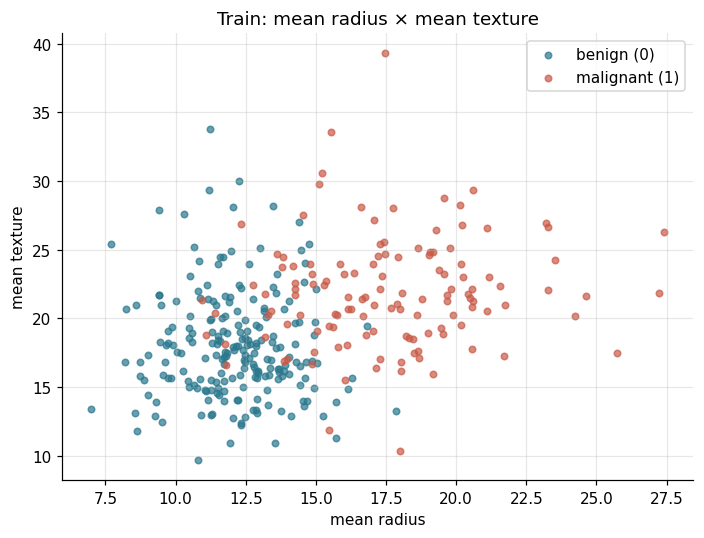

In [ ]:
display(cls_X_train.agg(["min", "max", "mean", "std"]).T.round(2))

cls_class_share = pd.DataFrame({
    "число": cls_y_train.value_counts().sort_index(),
    "доля": cls_y_train.value_counts(normalize=True).sort_index(),
}).rename(index=cls_names)
display(cls_class_share.round(3))

# Средние признаков по классам
display(cls_X_train.groupby(cls_y_train).mean().rename(index=cls_names).round(2))

fig, ax = plt.subplots(figsize=(6.5, 5))
for label in [0, 1]:
    mask = cls_y_train == label
    ax.scatter(cls_X_train.loc[mask, cls_features[0]],
               cls_X_train.loc[mask, cls_features[1]],
               color=cls_colors[label], s=18, alpha=0.7, label=cls_names[label])
ax.set(xlabel=cls_features[0], ylabel=cls_features[1],
       title="Train: mean radius × mean texture")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score as cls_accuracy_score

# Класс большинства определяется по train
cls_majority = cls_DummyClassifier(strategy="most_frequent").fit(cls_X_train, cls_y_train)
print("Класс большинства на train:", cls_majority.classes_[np.argmax(cls_majority.class_prior_)])

cls_rows = []
for cls_split, (cls_Xs, cls_ys) in {"train": (cls_X_train, cls_y_train),
                                    "validation": (cls_X_val, cls_y_val)}.items():
    cls_pred = cls_majority.predict(cls_Xs)
    cls_rows.append({
        "выборка": cls_split,
        "accuracy": cls_accuracy_score(cls_ys, cls_pred),
        "recall (класс 1)": cls_recall_score(cls_ys, cls_pred, pos_label=1, zero_division=0),
        "balanced accuracy": cls_balanced_accuracy_score(cls_ys, cls_pred),
    })
display(pd.DataFrame(cls_rows).set_index("выборка").round(3))

Класс большинства на train: 0


,accuracy,recall (класс 1),balanced accuracy
выборка,,,
train,0.628,0.0,0.5
validation,0.623,0.0,0.5


1. Ошибки классификатора можно ожидать в области $(x, y) \in (10.0, 15.0) \times (15, 25) \cup (15.0, 17.5) \times (15, 20)$, так как встречается ситуация: точка одного класса окружена близкими точками другого класса.
2. Наименее информативна accuracy: для правила «всегда класс большинства» она равна доле класса 0 (0.628 на train, 0.623 на validation) и выглядит прилично, хотя правило не находит ни одной злокачественной опухоли. Это показывают recall класса 1, равный 0, и balanced accuracy, равная 0.5, — уровень любого константного классификатора. Поэтому при дисбалансе классов основная метрика — balanced accuracy.

### 4.2. Сравнение классификаторов и подбор гиперпараметров

Сравниваются логистическая регрессия, kNN, SVM с RBF-ядром и дерево решений.
Гиперпараметры для исследования выбраны самостоятельно, их значения подбираются
по validation balanced accuracy: для каждого метода — не менее трёх
значений хотя бы одного гиперпараметра, определяющего сложность или структуру
модели. Выбранные модели сохраняются, результаты сравнения сведены в таблицы.

Границы выбранных моделей строятся функцией `cls_plot_boundaries(models)`.

Отдельно исследуется влияние глубины дерева на train и validation balanced accuracy;
диапазон глубин выбран самостоятельно, результаты — на графике.

1. Чем обоснован выбор настроек и чем объясняются различия форм границ четырёх моделей?
2. Как одна из областей ошибок на validation объясняется формой границы?
3. Как интерпретировать зависимости метрик от глубины дерева?

In [ ]:
from sklearn.base import clone as cls_clone
from sklearn.model_selection import ParameterGrid as cls_ParameterGrid
def cls_scaled(est):
    return cls_Pipeline([("scaler", cls_StandardScaler()), ("model", est)])

# kNN и SVM работают с расстояниями, логрегрессия — со штрафом на веса,
# поэтому им нужна стандартизация. Дереву она не нужна.
cls_search_space = {
    "Логистическая регрессия": (
        cls_scaled(cls_LogisticRegression(max_iter=1000)),
        {"model__C": [0.001, 0.01, 0.1, 1, 10, 100],
         "model__class_weight": [None, "balanced"]}),
    "kNN": (
        cls_scaled(cls_KNeighborsClassifier()),
        {"model__n_neighbors": [1, 3, 5, 9, 15, 25, 41, 61],
         "model__weights": ["uniform", "distance"]}),
    "SVM (RBF)": (
        cls_scaled(cls_SVC(kernel="rbf")),
        {"model__C": [0.1, 1, 10, 100],
         "model__gamma": [0.01, 0.1, 1, 10],
         "model__class_weight": [None, "balanced"]}),
    "Дерево решений": (
        cls_DecisionTreeClassifier(random_state=SEED),
        {"max_depth": [1, 2, 3, 4, 5, 6, 8, None],
         "min_samples_leaf": [1, 5, 10, 20],
         "class_weight": [None, "balanced"]}),
}

cls_search_results, cls_best_models, cls_summary_rows = {}, {}, []
for cls_name, (cls_template, cls_param_grid) in cls_search_space.items():
    cls_rows = []
    for cls_params in cls_ParameterGrid(cls_param_grid):
        cls_model = cls_clone(cls_template).set_params(**cls_params).fit(cls_X_train, cls_y_train)
        cls_pred_val = cls_model.predict(cls_X_val)
        cls_rows.append({
            **{k.replace("model__", ""): ("None" if v is None else v) for k, v in cls_params.items()},
            "BA train": cls_balanced_accuracy_score(cls_y_train, cls_model.predict(cls_X_train)),
            "BA val": cls_balanced_accuracy_score(cls_y_val, cls_pred_val),
            "recall val": cls_recall_score(cls_y_val, cls_pred_val, zero_division=0),
            "precision val": cls_precision_score(cls_y_val, cls_pred_val, zero_division=0),
            "_model": cls_model,
        })
    cls_df = pd.DataFrame(cls_rows)
    cls_search_results[cls_name] = cls_df.drop(columns="_model")

    # Лучшая по BA val; при равенстве — меньший разрыв между train и val
    cls_df["gap"] = cls_df["BA train"] - cls_df["BA val"]
    cls_best = cls_df.sort_values(["BA val", "gap"], ascending=[False, True], kind="stable").iloc[0]
    cls_best_models[cls_name] = cls_best["_model"]

    cls_param_names = [k.replace("model__", "") for k in cls_param_grid]
    cls_summary_rows.append({
        "Метод": cls_name,
        "Гиперпараметры": ", ".join(f"{k}={cls_best[k]}" for k in cls_param_names),
        **{k: cls_best[k] for k in ["BA train", "BA val", "recall val", "precision val"]},
    })

cls_summary = pd.DataFrame(cls_summary_rows).set_index("Метод")
display(cls_summary.round(3))

# Лучшие конфигурации каждого метода
for cls_name, cls_df in cls_search_results.items():
    print(cls_name)
    display(cls_df.sort_values("BA val", ascending=False).head(5).round(3))

,Гиперпараметры,BA train,BA val,recall val,precision val
Метод,,,,,
Логистическая регрессия,"C=1.0, class_weight=None",0.881,0.860,0.791,0.872
kNN,"n_neighbors=9, weights=uniform",0.876,0.879,0.814,0.897
SVM (RBF),"C=0.1, gamma=1.0, class_weight=None",0.891,0.886,0.814,0.921
Дерево решений,"max_depth=3, min_samples_leaf=20, class_weight...",0.896,0.890,0.837,0.900


Логистическая регрессия


,C,class_weight,BA train,BA val,recall val,precision val
8,10.0,None,0.885,0.860,0.791,0.872
6,1.0,None,0.881,0.860,0.791,0.872
5,0.1,balanced,0.891,0.855,0.837,0.800
7,1.0,balanced,0.895,0.855,0.837,0.800
11,100.0,balanced,0.890,0.855,0.837,0.800


kNN


,n_neighbors,weights,BA train,BA val,recall val,precision val
6,9,uniform,0.876,0.879,0.814,0.897
12,41,uniform,0.884,0.879,0.814,0.897
8,15,uniform,0.892,0.872,0.814,0.875
11,25,distance,1.000,0.872,0.814,0.875
10,25,uniform,0.891,0.872,0.814,0.875


SVM (RBF)


,C,class_weight,gamma,BA train,BA val,recall val,precision val
2,0.1,None,1.00,0.891,0.886,0.814,0.921
25,100.0,None,0.10,0.892,0.886,0.814,0.921
24,100.0,None,0.01,0.890,0.879,0.814,0.897
10,1.0,None,1.00,0.895,0.879,0.814,0.897
21,10.0,balanced,0.10,0.889,0.876,0.837,0.857


Дерево решений


,class_weight,max_depth,min_samples_leaf,BA train,BA val,recall val,precision val
15,None,4,20,0.896,0.89,0.837,0.9
11,None,3,20,0.896,0.89,0.837,0.9
23,None,6,20,0.896,0.89,0.837,0.9
19,None,5,20,0.896,0.89,0.837,0.9
27,None,8,20,0.896,0.89,0.837,0.9


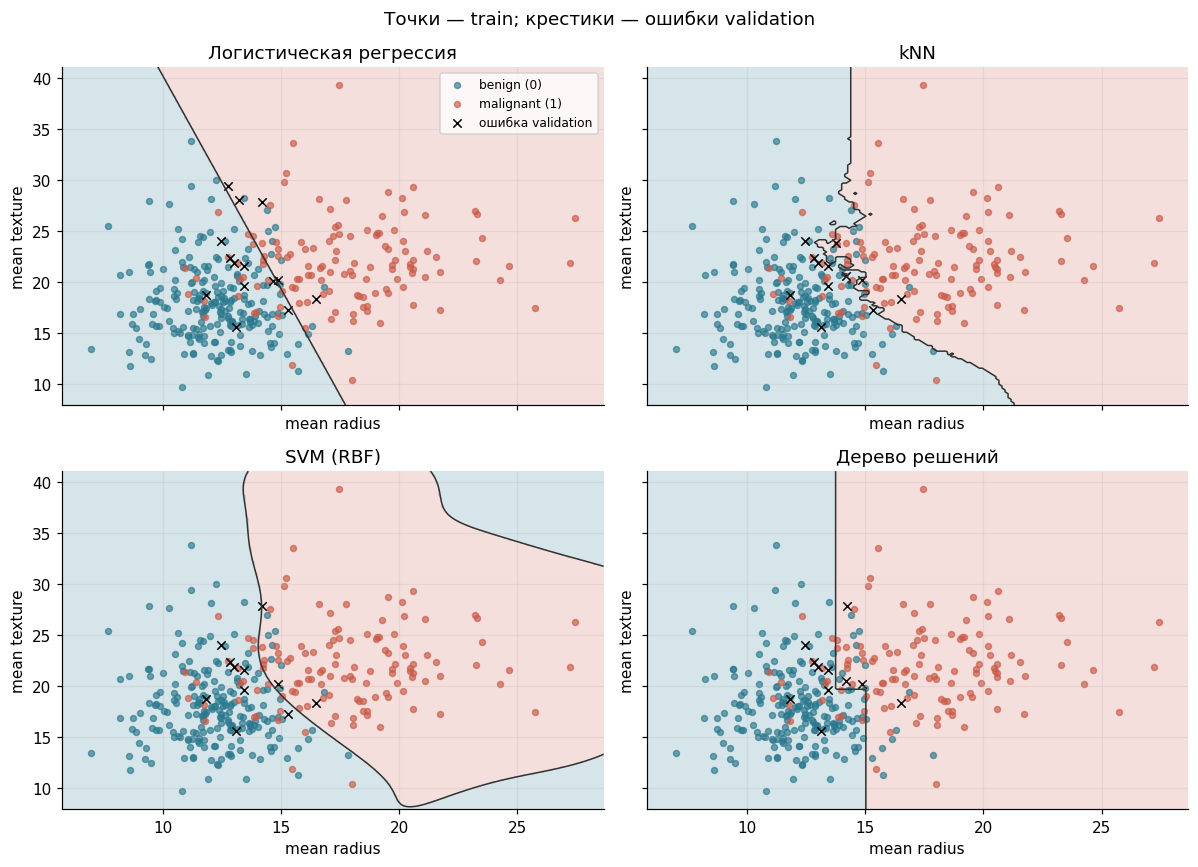

In [ ]:
cls_plot_boundaries(cls_best_models)

,max_depth,фактическая глубина,листьев,BA train,BA val
0,1,1,2,0.873,0.865
1,2,2,4,0.876,0.842
2,3,3,8,0.880,0.853
3,4,4,14,0.906,0.821
4,5,5,21,0.927,0.807
5,6,6,30,0.954,0.839
6,7,7,40,0.986,0.820
7,8,8,43,0.990,0.820
8,9,9,47,0.996,0.832
9,10,10,48,1.000,0.820


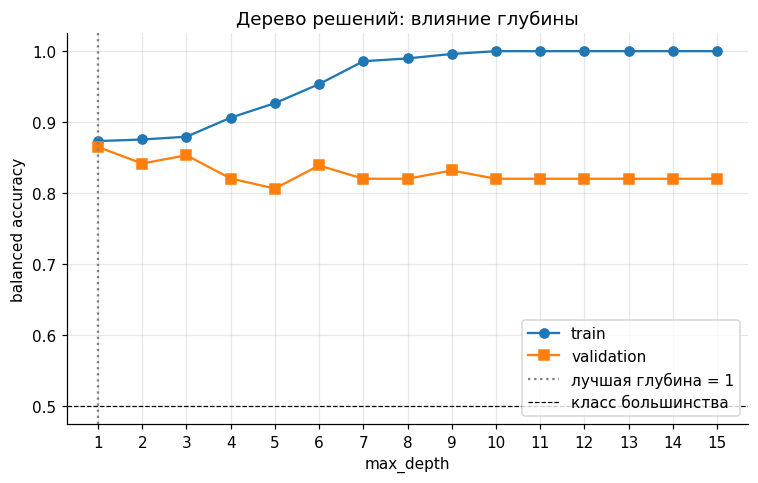

In [ ]:
cls_depths = list(range(1, 16))
cls_depth_rows = []
for cls_d in cls_depths + [None]:
    cls_tree = cls_DecisionTreeClassifier(max_depth=cls_d, random_state=SEED).fit(cls_X_train, cls_y_train)
    cls_depth_rows.append({
        "max_depth": "None" if cls_d is None else cls_d,
        "фактическая глубина": cls_tree.get_depth(),
        "листьев": cls_tree.get_n_leaves(),
        "BA train": cls_balanced_accuracy_score(cls_y_train, cls_tree.predict(cls_X_train)),
        "BA val": cls_balanced_accuracy_score(cls_y_val, cls_tree.predict(cls_X_val)),
    })
cls_depth_df = pd.DataFrame(cls_depth_rows)
display(cls_depth_df.round(3))

cls_plot_df = cls_depth_df[cls_depth_df["max_depth"] != "None"]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(cls_plot_df["max_depth"], cls_plot_df["BA train"], "o-", label="train")
ax.plot(cls_plot_df["max_depth"], cls_plot_df["BA val"], "s-", label="validation")
cls_best_d = cls_plot_df.loc[cls_plot_df["BA val"].idxmax(), "max_depth"]
ax.axvline(cls_best_d, color="gray", ls=":", label=f"лучшая глубина = {cls_best_d}")
ax.axhline(0.5, color="black", lw=0.8, ls="--", label="класс большинства")
ax.set(xlabel="max_depth", ylabel="balanced accuracy",
       title="Дерево решений: влияние глубины", xticks=cls_depths)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

1. У классификатора на основе логистической регрессии граница — прямая, что естественно. У классификатора на основе kNN граница — ломаная, лежащая на рёбрах диаграммы Вороного порядка $k$ (здесь $k = 9$), построенной по train в стандартизованных координатах; обычная диаграмма Вороного получается только при $k = 1$. У классификатора на основе решающего дерева граница — ломаная, состоящая из отрезков прямых, параллельных осям координат. У SVM с RBF-ядром граница — линия уровня некоторой гладкой функции.
2. Ошибки validation — объекты класса 1, окруженные объектами класса 0. Нельзя построить границы соответствующих типов так, чтобы, избежав этих ошибок, не понизить точность на train.
3. Решающее дерево достаточно большой глубины запоминает train, давая BA = 1, но хуже работает на validation — происходит переобучение.

### 4.3. Масштаб признаков: kNN и дерево решений

В копиях train и validation только `mean radius` умножается на `100`.
На исходных и преобразованных данных обучается по одной версии:

- kNN с `n_neighbors=9` без стандартизации;
- kNN с `n_neighbors=9` и `StandardScaler`;
- дерева с `max_depth=3`, `random_state=SEED`.

Для каждого метода вычисляется доля validation-объектов, у которых изменилась
предсказанная метка. Две границы kNN без стандартизации изображены
в исходных координатах: `cls_plot_boundaries` вызывается с
`radius_multipliers={название_преобразованной_модели: 100}` и `mark_errors=False`.

Как объясняются результаты для каждого метода и какова роль масштаба признаков?

,доля изменившихся меток,изменилось объектов,BA val (исходные),BA val (radius×100)
Метод,,,,
kNN (k=9) без стандартизации,0.061,7,0.886,0.851
kNN (k=9) + StandardScaler,0.000,0,0.879,0.879
Дерево (max_depth=3),0.000,0,0.853,0.853


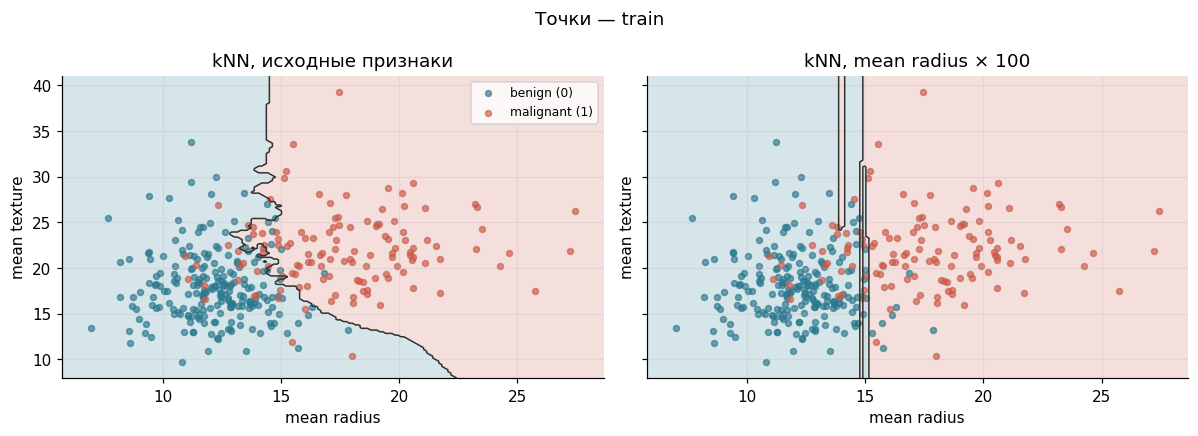

In [ ]:
from sklearn.base import clone as cls_clone

# Копии train и validation, в которых mean radius умножен на 100
cls_X_train_r100 = cls_X_train.copy()
cls_X_val_r100 = cls_X_val.copy()
cls_X_train_r100["mean radius"] *= 100
cls_X_val_r100["mean radius"] *= 100

cls_scale_variants = {
    "kNN (k=9) без стандартизации": cls_KNeighborsClassifier(n_neighbors=9),
    "kNN (k=9) + StandardScaler": cls_Pipeline([
        ("scaler", cls_StandardScaler()),
        ("model", cls_KNeighborsClassifier(n_neighbors=9)),
    ]),
    "Дерево (max_depth=3)": cls_DecisionTreeClassifier(max_depth=3, random_state=SEED),
}

cls_scale_models, cls_scale_rows = {}, []
for cls_name, cls_template in cls_scale_variants.items():
    # Отдельная модель для исходных данных и отдельная для radius × 100
    cls_m_orig = cls_clone(cls_template).fit(cls_X_train, cls_y_train)
    cls_m_r100 = cls_clone(cls_template).fit(cls_X_train_r100, cls_y_train)
    cls_scale_models[cls_name] = (cls_m_orig, cls_m_r100)

    # Validation в тех же единицах, что и соответствующий train
    cls_pred_orig = cls_m_orig.predict(cls_X_val)
    cls_pred_r100 = cls_m_r100.predict(cls_X_val_r100)

    cls_scale_rows.append({
        "Метод": cls_name,
        "доля изменившихся меток": float(np.mean(cls_pred_orig != cls_pred_r100)),
        "изменилось объектов": int(np.sum(cls_pred_orig != cls_pred_r100)),
        "BA val (исходные)": cls_balanced_accuracy_score(cls_y_val, cls_pred_orig),
        "BA val (radius×100)": cls_balanced_accuracy_score(cls_y_val, cls_pred_r100),
    })

display(pd.DataFrame(cls_scale_rows).set_index("Метод").round(3))

# Границы kNN без стандартизации в исходных координатах
cls_knn_orig, cls_knn_r100 = cls_scale_models["kNN (k=9) без стандартизации"]
cls_plot_boundaries(
    {"kNN, исходные признаки": cls_knn_orig,
     "kNN, mean radius × 100": cls_knn_r100},
    radius_multipliers={"kNN, mean radius × 100": 100},
    mark_errors=False,
)

При использовании kNN без стандартизации и при масштабировании признаков метки могут измениться, потому что меняется функция расстояния между векторами признаков. При использовании kNN со стандартизацией метрика не меняется и результат сохраняется. При использовании дерева решений масштаб признаков не влияет на результат классификации.

### 4.4. Выбор порога логистической регрессии

Для обученной логистической регрессии из 4.2 вычисляются оценки вероятности
класса 1 на validation; для порога $t$ используется правило $\hat y=1$ при $p(x)\ge t$.
Строятся зависимости precision и recall от порога на отрезке $[0,1]$.

Для порогов `0.2, 0.5, 0.8` — таблица: precision, recall, FP, FN.
При отсутствии положительных предсказаний используется `zero_division=0`.

1. Как FP и FN зависят от порога? Монотонны ли precision и recall? Каков смысл `zero_division=0`?
2. Какой из трёх порогов выбрать, если пропуск класса 1 значительно дороже ложного срабатывания? Какие данные нужны для численного обоснования выбора?
3. Как изменение порога влияет на вероятностные оценки, ранжирование объектов и границу классификации?

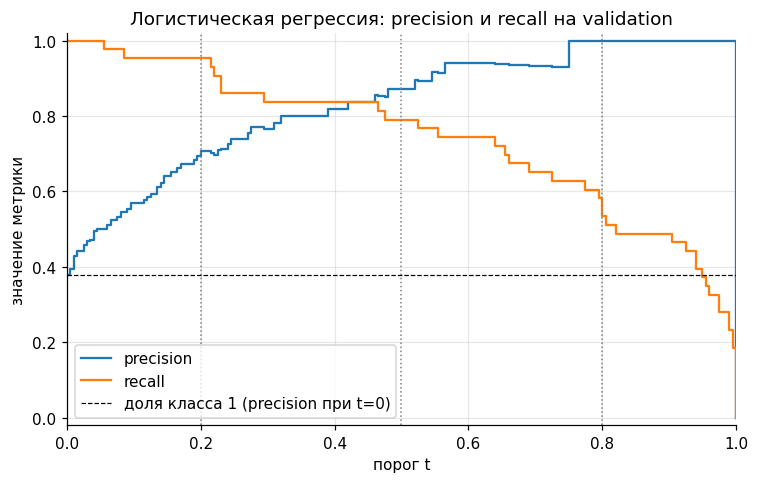

,precision,recall,FP,FN
порог,,,,
0.2,0.707,0.953,17,2
0.5,0.872,0.791,5,9
0.8,1.000,0.535,0,20


In [ ]:
cls_logreg = cls_best_models["Логистическая регрессия"]
cls_proba_val = cls_logreg.predict_proba(cls_X_val)[:, 1]   # оценка P(y=1 | x)

def cls_threshold_metrics(t):
    pred = (cls_proba_val >= t).astype(int)                  # ŷ = 1 при p(x) ≥ t
    tn, fp, fn, tp = cls_confusion_matrix(cls_y_val, pred, labels=[0, 1]).ravel()
    return {
        "порог": t,
        "precision": cls_precision_score(cls_y_val, pred, zero_division=0),
        "recall": cls_recall_score(cls_y_val, pred, zero_division=0),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }

cls_thresholds = np.linspace(0, 1, 201)
cls_curve = pd.DataFrame([cls_threshold_metrics(t) for t in cls_thresholds])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(cls_curve["порог"], cls_curve["precision"], label="precision", drawstyle="steps-post")
ax.plot(cls_curve["порог"], cls_curve["recall"], label="recall", drawstyle="steps-post")
for t in [0.2, 0.5, 0.8]:
    ax.axvline(t, color="gray", ls=":", lw=1)
ax.axhline(cls_y_val.mean(), color="black", ls="--", lw=0.8,
           label="доля класса 1 (precision при t=0)")
ax.set(xlabel="порог t", ylabel="значение метрики", xlim=(0, 1), ylim=(-0.02, 1.02),
       title="Логистическая регрессия: precision и recall на validation")
ax.grid(alpha=0.3)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

cls_thr_table = pd.DataFrame([cls_threshold_metrics(t) for t in [0.2, 0.5, 0.8]]).set_index("порог")
display(cls_thr_table[["precision", "recall", "FP", "FN"]].round(3))

1. FP не возрастает с ростом порога, FN, напротив, не убывает. Recall не возрастает, как и ожидалось по результатам пункта 2.1. Precision растет в зависимости от порога, достигая 1.
2. Важнее всего recall, поэтому стоит выбрать порог 0.2.
3. На оценку вероятности изменение порога не повлияет никак, на ранжирование объектов в соответствии с этой оценкой тоже, а граница — прямая $w^\top x+b=\ln\frac{t}{1-t}$ — с увеличением порога сдвигается параллельно в сторону класса 1.

### 4.5. Выбор модели и финальная оценка на test

По validation balanced accuracy выбирается одна из четырёх моделей с подобранными
в пункте 4.2 гиперпараметрами; выбор фиксируется и обосновывается до обращения к test, используется обычный `predict`.

На test оцениваются выбранная модель и `DummyClassifier(strategy="most_frequent")`,
обученный на train: balanced accuracy, precision и recall класса 1 —
в таблице, для выбранной модели — матрица ошибок.
Для precision используется `zero_division=0`.

1. Какие ошибки преобладают? Как соотносятся матрица ошибок и рассчитанные метрики?
2. Чем объясняется различие test и validation balanced accuracy?

,BA validation
Дерево решений,0.890
SVM (RBF),0.886
kNN,0.879
Логистическая регрессия,0.860


,balanced accuracy,precision (класс 1),recall (класс 1)
Модель,,,
Дерево решений,0.877,0.895,0.81
Dummy (most_frequent),0.500,0.000,0.00


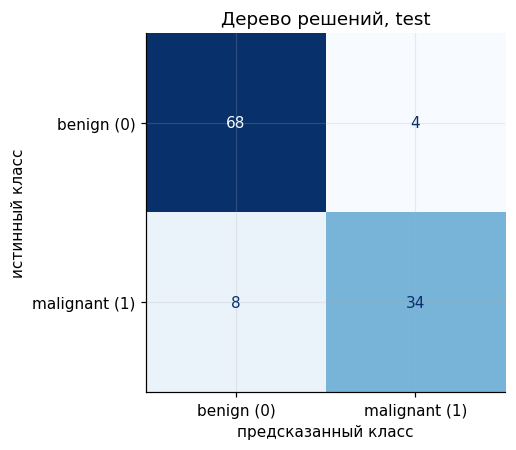

In [ ]:
# Выбор зафиксирован до обращения к test
cls_val_ba = pd.Series({
    cls_name: cls_balanced_accuracy_score(cls_y_val, cls_model.predict(cls_X_val))
    for cls_name, cls_model in cls_best_models.items()
}).sort_values(ascending=False)
display(cls_val_ba.round(3).to_frame("BA validation"))

cls_final_name = "Дерево решений"
cls_final_model = cls_best_models[cls_final_name]

cls_dummy = cls_DummyClassifier(strategy="most_frequent").fit(cls_X_train, cls_y_train)

cls_rows = []
for cls_name, cls_model in {cls_final_name: cls_final_model,
                            "Dummy (most_frequent)": cls_dummy}.items():
    cls_pred = cls_model.predict(cls_X_test)
    cls_rows.append({
        "Модель": cls_name,
        "balanced accuracy": cls_balanced_accuracy_score(cls_y_test, cls_pred),
        "precision (класс 1)": cls_precision_score(cls_y_test, cls_pred, zero_division=0),
        "recall (класс 1)": cls_recall_score(cls_y_test, cls_pred),
    })
display(pd.DataFrame(cls_rows).set_index("Модель").round(3))

cls_pred_test = cls_final_model.predict(cls_X_test)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
cls_ConfusionMatrixDisplay.from_predictions(
    cls_y_test, cls_pred_test,
    display_labels=["benign (0)", "malignant (1)"],
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set(title=f"{cls_final_name}, test",
       xlabel="предсказанный класс", ylabel="истинный класс")
plt.tight_layout()
plt.show()

1. Преобладает ошибка FN: 8 пропущенных злокачественных опухолей против 4 ложных срабатываний, а это самая дорогая ошибка в задаче. Значения метрик можно вычислить исходя из табличных данных.
2. Test balanced accuracy ниже validation balanced accuracy просто потому, что модель для запуска на test выбралась исходя из результата validation.

## Выводы и дальнейшая работа

Итоги экспериментов, ограничения и направления дальнейшего исследования.

**Выводы:**
- Регуляризация на Diabetes не помогла: OLS не переобучается (10 признаков на 265 объектов) и остаётся лучшей моделью — RMSE на test 57.0 против 76.9 у константного прогноза.
- Масштаб признаков важен для моделей со штрафом и для kNN: без стандартизации Ridge и kNN меняют прогнозы при смене единиц измерения, OLS и дерево — нет.
- При коррелирующих признаках коэффициенты линейной модели неустойчивы (`s1` и `s2`), их нельзя читать как важность или причинный эффект.
- На Breast Cancer по двум признакам четыре классификатора близки (balanced accuracy 0.86–0.89 на validation, разница в пределах шума); итоговое дерево даёт 0.877 на test против 0.5 у константы. Основная ошибка — пропуск злокачественных опухолей, поэтому порог стоит выбирать по стоимости ошибок.
- Ограничения: маленькие выборки, одно разбиение, два признака из 30, калибровка вероятностей не проверялась.
- Дальше: кросс-валидация с доверительными интервалами, все 30 признаков, калибровка и выбор порога по стоимости ошибок.